# 01b · Target definition, time split & drift check: BankSight

**What this notebook does**
1. Defines the prediction target (`got_relief`) explicitly and builds `features.complaint_labels` in the warehouse.
2. Freezes the train / validation / test dates.
3. Checks *why* the test period has a lower relief rate than training (product mix vs real change).
4. Writes `configs/config.yaml` with every modelling decision, so later notebooks read them from one place.

**What this does:** imports every library used in the notebook and sets how pandas prints tables. Imports live only in this cell.

In [1]:
from datetime import date
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

**What this does:** works out where the project files live and makes sure the output folders exist.
The notebook sits in `notebooks/`, so the project root is one folder up.

In [2]:
if Path.cwd().name == "notebooks":
    ROOT = Path("..")
else:
    ROOT = Path(".")
PARQUET = ROOT / "data" / "processed" / "cfpb_sample.parquet"
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
FEATURES_DIR = ROOT / "data" / "features"

for folder in [WAREHOUSE.parent, FEATURES_DIR, ROOT / "configs"]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. The frozen decisions
**Rule:** these dates and definitions are set *now*, before any model is trained. Never change them after seeing model
results, because that would quietly tune the test set.

**What this does:** fixes the two split dates and the exact `company_response` values that mean relief (target = 1),
no relief (target = 0), or "no final outcome" (excluded). Everything later uses these lists.

In [3]:
VAL_START = "2025-07-01"   # train      = date_received <  VAL_START
TEST_START = "2025-11-01"  # validation = VAL_START <= date_received < TEST_START ; test = date_received >= TEST_START
SPLITS = ["train", "validation", "test"]

RELIEF = ["Closed with monetary relief", "Closed with non-monetary relief"]  # target = 1
NO_RELIEF = ["Closed with explanation"]                                      # target = 0
FINAL = RELIEF + NO_RELIEF                                                   # rows with a final outcome
NOT_FINAL = ["Untimely response", "In progress"]                             # excluded (no final outcome)

**What this does:** turns each Python list into text like `'a', 'b'` so it can be pasted into a SQL `IN (...)` filter.
(None of these values contain an apostrophe, so no escaping is needed.)

In [4]:
relief_sql = ", ".join("'" + value + "'" for value in RELIEF)
no_relief_sql = ", ".join("'" + value + "'" for value in NO_RELIEF)
final_sql = ", ".join("'" + value + "'" for value in FINAL)
print(relief_sql)
print(no_relief_sql)
print(final_sql)

'Closed with monetary relief', 'Closed with non-monetary relief'
'Closed with explanation'
'Closed with monetary relief', 'Closed with non-monetary relief', 'Closed with explanation'


## 2. Build the labels table
Relief is matched against an **explicit list** of values (not a text search for the word "relief"), so an unexpected value
such as "Closed without relief" can never be counted as relief by accident.

**What this does:** opens the DuckDB warehouse and, only if `raw.cfpb_complaints` is missing, rebuilds it from the parquet file.
A *schema* is a folder-like group of tables inside the database.

In [5]:
con = duckdb.connect(str(WAREHOUSE))
con.execute("CREATE SCHEMA IF NOT EXISTS raw")
con.execute("CREATE SCHEMA IF NOT EXISTS features")

table_rows = con.sql("SELECT table_schema || '.' || table_name FROM information_schema.tables").fetchall()
existing_tables = []
for table_row in table_rows:
    existing_tables.append(table_row[0])

if "raw.cfpb_complaints" not in existing_tables:
    assert PARQUET.exists(), f"Not found: {PARQUET.resolve()}"
    con.execute(f"CREATE TABLE raw.cfpb_complaints AS SELECT * FROM read_parquet('{PARQUET.as_posix()}')")
    print("raw.cfpb_complaints was missing, rebuilt from the parquet file")

**What this does:** a safety check. It lists every distinct `company_response` and warns if any value is not in our
relief / no-relief / not-final lists, because such rows would be silently left out of the target.

In [6]:
seen = con.sql("SELECT company_response, count(*) AS n FROM raw.cfpb_complaints GROUP BY 1 ORDER BY 2 DESC").df()
known_values = set(FINAL) | set(NOT_FINAL)
is_known = seen["company_response"].isin(known_values)
unknown = seen[seen["company_response"].notna() & ~is_known]
if len(unknown) > 0:
    print("WARNING: these company_response values are not classified and will be EXCLUDED from the target:")
    display(unknown)
else:
    print("All company_response values are classified (nothing unexpected).")

All company_response values are classified (nothing unexpected).


**What this does:** creates the table `features.complaint_labels` with one row per complaint: whether it has a final outcome
(`target_eligible`), the target `got_relief` (1/0), a secondary target `got_monetary_relief`, and the `split` name from the date.

In [7]:
con.execute(f"""
CREATE OR REPLACE TABLE features.complaint_labels AS
SELECT
    complaint_id,
    date_received,
    product_group,
    COALESCE(company_response IN ({final_sql}), FALSE) AS target_eligible,
    CASE WHEN company_response IN ({relief_sql})    THEN 1
         WHEN company_response IN ({no_relief_sql}) THEN 0 END AS got_relief,
    CASE WHEN company_response = 'Closed with monetary relief' THEN 1
         WHEN company_response IN ({final_sql})                THEN 0 END AS got_monetary_relief,
    CASE WHEN date_received IS NULL                 THEN NULL
         WHEN date_received <  DATE '{VAL_START}'   THEN 'train'
         WHEN date_received <  DATE '{TEST_START}'  THEN 'validation'
         ELSE 'test' END AS split
FROM raw.cfpb_complaints
""")
print("features.complaint_labels created")

features.complaint_labels created


**What this does:** checks that no row is missing a date (so every row got a split) and that no `complaint_id` is duplicated.
The notebook stops with an error if either check fails.

In [8]:
rows_without_split = con.sql("SELECT count(*) FROM features.complaint_labels WHERE split IS NULL").fetchone()[0]
duplicate_ids = con.sql("SELECT count(*) - count(DISTINCT complaint_id) FROM features.complaint_labels").fetchone()[0]
assert rows_without_split == 0, "rows with no date"
assert duplicate_ids == 0, "duplicate ids"
print("checks passed: every row has a split, no duplicate ids")

checks passed: every row has a split, no duplicate ids


**What this does:** prints, for each split, the number of rows, the number with a final outcome (eligible),
the number with relief, and the relief rate in percent. Also prints the overall totals.

In [9]:
summary = con.sql("""
    SELECT split,
           count(*)                                                       AS rows,
           sum(target_eligible::INT)                                      AS eligible,
           sum(got_relief)                                                AS relief,
           round(100.0 * sum(got_relief) / sum(target_eligible::INT), 2) AS relief_pct
    FROM features.complaint_labels
    GROUP BY 1
    ORDER BY CASE split WHEN 'train' THEN 1 WHEN 'validation' THEN 2 ELSE 3 END
""").df()
tot = summary[["rows", "eligible", "relief"]].sum()
print(f"total rows {int(tot['rows']):,} | eligible {int(tot['eligible']):,} | excluded {int(tot['rows'] - tot['eligible']):,}")
display(summary)

total rows 150,000 | eligible 148,766 | excluded 1,234


,split,rows,eligible,relief,relief_pct
0,train,104130,103777.0,24600.0,23.70
1,validation,18802,18537.0,4222.0,22.78
2,test,27068,26452.0,4850.0,18.34


## 3. Why is the test relief rate lower?
Overall, the relief rate drops in the test period. Two different things can cause that:
* **Mix effect:** the product mix changed (e.g. fewer credit-reporting complaints, which get relief far more often).
* **Within-product effect:** complaints in the *same* product are now resolved differently (a real change in behaviour).

Below we separate the two. Neither is a modelling error, but they need different explanations in the model card.

**What this does:** loads the labels table into pandas `d`, joined with the raw `company_response` and `timely_response`
columns (`company` is not selected on purpose). Then it keeps only the eligible rows in `elig`.

In [10]:
d = con.sql("""
    SELECT l.complaint_id, l.date_received, l.product_group, l.target_eligible, l.got_relief, l.split,
           r.company_response, r.timely_response
    FROM features.complaint_labels l JOIN raw.cfpb_complaints r USING (complaint_id)
""").df()
d["date_received"] = pd.to_datetime(d["date_received"])
d["split"] = pd.Categorical(d["split"], SPLITS, ordered=True)  # ordered so tables list train, validation, test
elig = d[d["target_eligible"]].copy()
elig["got_relief"] = elig["got_relief"].astype(int)
print(f"modelling rows: {len(elig):,}")

modelling rows: 148,766


### 3a. Relief rate by month
A **step change** points to a policy or process change on a specific date; a **slow slide** points to gradual drift.

**What this does:** for each month, counts eligible complaints and computes the relief rate in percent, shown as a table.

In [11]:
monthly = elig.groupby(elig["date_received"].dt.to_period("M"))["got_relief"].agg(n="size", relief_pct="mean")
monthly["relief_pct"] = (monthly["relief_pct"] * 100).round(2)
display(monthly.T)

date_received,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,...,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
n,2573.00,2033.00,2342.00,1939.00,2188.00,2212.00,2271.00,2555.00,2431.00,2685.00,2408.00,2454.00,2595.00,2597.00,3219.00,...,4531.00,4646.00,5216.00,4900.00,4347.00,4074.00,4176.0,3406.00,3478.00,1857.00,3221.00,3390.00,2712.00,2665.00,1547.0
relief_pct,18.58,20.66,21.48,21.35,23.08,25.59,26.64,26.38,25.34,25.33,25.42,25.47,26.94,27.26,30.66,...,25.82,27.31,26.27,22.57,21.85,19.54,22.1,20.41,16.01,16.64,15.93,15.72,18.77,18.76,20.1


**What this does:** plots the monthly relief rate as a line, with dashed vertical lines where validation and test start.

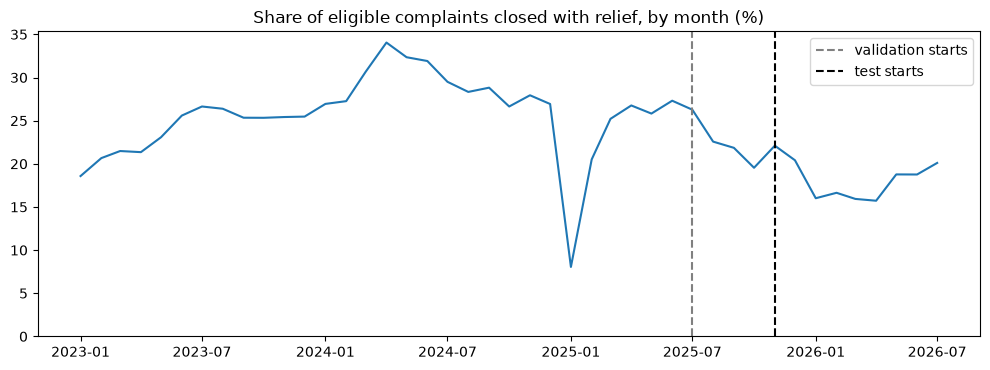

In [12]:
month_dates = monthly.index.to_timestamp()
plt.figure(figsize=(10, 3.8))
plt.plot(month_dates, monthly["relief_pct"])
plt.axvline(pd.Timestamp(VAL_START), color="grey", linestyle="--", label="validation starts")
plt.axvline(pd.Timestamp(TEST_START), color="black", linestyle="--", label="test starts")
plt.ylim(bottom=0)
plt.title("Share of eligible complaints closed with relief, by month (%)")
plt.legend()
plt.tight_layout()
plt.show()

### 3b. Product mix and relief rate by split

**What this does:** shows (1) what share of each split each product makes up, and (2) the relief rate of each product
in each split. Products are listed from biggest to smallest in train.

In [13]:
mix = (pd.crosstab(elig["product_group"], elig["split"], normalize="columns") * 100).round(1)[SPLITS]
rate = elig.pivot_table(index="product_group", columns="split", values="got_relief", aggfunc="mean", observed=True)
rate = (rate * 100).round(1)[SPLITS]

mix_sorted = mix.sort_values("train", ascending=False)
print("Share of complaints by product (% of each split):")
display(mix_sorted)
print("Relief rate by product (%):")
display(rate.loc[mix_sorted.index])

Share of complaints by product (% of each split):


split,train,validation,test
product_group,,,
Credit reporting,18.9,21.7,5.1
Credit or prepaid card,16.3,15.8,19.4
Bank account,16.1,15.2,20.6
Debt collection,15.1,20.3,20.2
Money transfer / virtual currency,15.1,9.4,11.0
Mortgage,6.6,5.7,8.3
Student loan,4.3,2.4,2.9
Vehicle loan or lease,4.2,5.0,6.6
Payday / personal loan,2.7,3.5,4.8


Relief rate by product (%):


split,train,validation,test
product_group,,,
Credit reporting,49.3,39.7,39.3
Credit or prepaid card,34.6,28.5,26.3
Bank account,18.4,17.1,19.6
Debt collection,25.6,25.7,20.1
Money transfer / virtual currency,4.9,9.7,15.2
Mortgage,4.9,3.8,4.8
Student loan,4.6,1.8,1.2
Vehicle loan or lease,8.3,7.7,9.3
Payday / personal loan,8.3,4.9,5.1


### 3c. Mix vs within-product effect  *(paste this table back)*
`if_only_mix_changed_%` = the rate we would expect if every product kept its **training** relief rate and only the mix moved.
* `mix_effect_pp` = how much of the change the product mix explains (percentage points).
* `within_product_effect_pp` = what is left, i.e. relief rates inside products changed.

**What this does:** for each split, computes the actual relief rate and the rate we would expect if each product kept its
training relief rate (only the mix changes). Products never seen in train fall back to the overall train rate.

In [14]:
train_rows = elig[elig["split"] == "train"]
train_rate_by_product = train_rows.groupby("product_group")["got_relief"].mean()
train_overall_rate = train_rows["got_relief"].mean()

result_rows = []
for split_name in SPLITS:
    split_rows = elig[elig["split"] == split_name]
    product_share = split_rows["product_group"].value_counts(normalize=True)
    train_rate_for_these = train_rate_by_product.reindex(product_share.index).fillna(train_overall_rate)
    expected_rate = float((product_share * train_rate_for_these).sum())
    result_rows.append({
        "split": split_name,
        "rows": len(split_rows),
        "actual_%": split_rows["got_relief"].mean() * 100,
        "if_only_mix_changed_%": expected_rate * 100,
    })
decomposition = pd.DataFrame(result_rows).set_index("split")

**What this does:** subtracts to split each change versus train into the part explained by product mix and the leftover
within-product part, then prints the table. `pp` means percentage points.

In [15]:
train_actual = decomposition.loc["train", "actual_%"]
decomposition["mix_effect_pp"] = decomposition["if_only_mix_changed_%"] - train_actual
decomposition["within_product_effect_pp"] = decomposition["actual_%"] - decomposition["if_only_mix_changed_%"]
display(decomposition.round(2))

,rows,actual_%,if_only_mix_changed_%,mix_effect_pp,within_product_effect_pp
split,,,,,
train,103777,23.70,23.70,0.00,0.00
validation,18537,22.78,25.80,2.10,-3.03
test,26452,18.34,20.36,-3.35,-2.02


### 3d. Other signals
The company table was removed on purpose (`company` is dropped).

**What this does:** among complaints that got relief, shows the share that was monetary (money back) in each split.

In [16]:
relief_rows = elig[elig["got_relief"] == 1].copy()
relief_rows["monetary"] = (relief_rows["company_response"] == "Closed with monetary relief").astype(int)
monetary_share = relief_rows.groupby("split", observed=True)["monetary"].mean() * 100
print("Share of relief that is monetary (%):")
display(monetary_share.round(1).to_frame("monetary_share_%").T)

Share of relief that is monetary (%):


split,train,validation,test
monetary_share_%,24.2,21.6,42.9


**What this does:** shows the percent of all complaints (not only eligible ones) with `timely_response = 'No'` in each split.

In [17]:
is_untimely = d["timely_response"] == "No"
untimely_percent = is_untimely.groupby(d["split"], observed=True).mean() * 100
print("Complaints where timely_response = 'No' (%), all rows:")
display(untimely_percent.round(2).to_frame("untimely_%").T)

Complaints where timely_response = 'No' (%), all rows:


split,train,validation,test
untimely_%,1.77,2.49,3.87


## 4. Freeze the decisions in `configs/config.yaml`
Later notebooks and scripts read this file instead of repeating dates and column names.

**Safe to re-run:** if `configs/config.yaml` already exists it is never overwritten; the new text goes to `config.proposed.yaml` instead.
The feature lists below are your final, manually edited version. Edit them here, not in the YAML file.

**What this does:** finds the last complaint date in the data and writes the first half of the config text
(data paths, split dates, target definition) into a string variable. Nothing is saved yet.

In [18]:
data_end = d["date_received"].max().date().isoformat()
today_text = date.today().isoformat()
excluded_values = NOT_FINAL + ["<missing>"]

CONFIG_TOP = f"""# BankSight frozen decisions: written by notebook 01b on {today_text}
# They were set BEFORE any model was trained. Do not change them after looking at model results.
project: banksight
seed: 42

data:
  sample_parquet: data/processed/cfpb_sample.parquet
  warehouse: data/warehouse/banksight.duckdb
  labels_table: features.complaint_labels
  labels_parquet: data/features/complaint_labels.parquet
  last_complaint_date: {data_end}

split:
  type: time                      # never a random split
  validation_start: {VAL_START}   # train < validation_start
  test_start: {TEST_START}        # validation < test_start <= test

target:
  name: got_relief
  positive: {RELIEF}
  negative: {NO_RELIEF}
  excluded: {excluded_values}
  secondary_target: got_monetary_relief
"""
print(CONFIG_TOP)

# BankSight frozen decisions: written by notebook 01b on 2026-10-11
# They were set BEFORE any model was trained. Do not change them after looking at model results.
project: banksight
seed: 42

data:
  sample_parquet: data/processed/cfpb_sample.parquet
  warehouse: data/warehouse/banksight.duckdb
  labels_table: features.complaint_labels
  labels_parquet: data/features/complaint_labels.parquet
  last_complaint_date: 2026-07-29

split:
  type: time                      # never a random split
  validation_start: 2025-07-01   # train < validation_start
  test_start: 2025-11-01        # validation < test_start <= test

target:
  name: got_relief
  positive: ['Closed with monetary relief', 'Closed with non-monetary relief']
  negative: ['Closed with explanation']
  excluded: ['Untimely response', 'In progress', '<missing>']
  secondary_target: got_monetary_relief



**What this does:** writes the second half of the config text: which columns models may use, which are leakage
(only known after the company answers), and which baselines to beat. This is your final, manually edited version.

In [19]:
CONFIG_FEATURES = """
features:
  allowed_at_prediction_time: [narrative, product_group, issue]
  excluded_from_model_kept_for_audit: [tags, state]
  not_useful: [narrative_length, xxxx_count]
  to_test: [sub_product, sub_issue]
  unusable: [company]                   # holds public-response text by mistake in this sample
  leakage_never_use: [company_response, company_public_response, timely_response]   # only known after the company answers
  redundant: [date_sent_to_company]     # almost identical to date_received
  constant_or_empty: [submitted_via, consumer_disputed]
  # NLP product/issue classifier: do not feed issue/sub_issue when the label is product_group

evaluation:
  primary_metric: pr_auc
  also_report: [roc_auc, brier_score, calibration_curve, pr_auc_within_each_product]
  baselines: [relief_rate_by_product, logistic_product_plus_issue, tfidf_logistic_text_product_issue]
  note: text must add lift over product + issue, otherwise it is not earning its place
"""
CONFIG = CONFIG_TOP + CONFIG_FEATURES

**What this does:** saves the config. If `configs/config.yaml` already exists with any content, it is NOT overwritten and the text goes
to `config.proposed.yaml` instead (compare the two yourself). If there is no config yet, it is created.

In [20]:
config_path = ROOT / "configs" / "config.yaml"
existing_text = ""
if config_path.exists():
    existing_text = config_path.read_text()

if existing_text.strip() != "":
    config_path = config_path.with_name("config.proposed.yaml")
    print("configs/config.yaml already exists, so it was left untouched; the new settings were saved to config.proposed.yaml")
config_path.write_text(CONFIG)
print("written:", config_path.resolve())

configs/config.yaml already exists, so it was left untouched; the new settings were saved to config.proposed.yaml
written: D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\configs\config.proposed.yaml


**What this does:** exports the labels table to `data/features/complaint_labels.parquet` for later notebooks, and closes the database.

In [21]:
out = FEATURES_DIR / "complaint_labels.parquet"
con.execute(f"COPY (SELECT * FROM features.complaint_labels) TO '{out.as_posix()}' (FORMAT PARQUET)")
print("saved", out.resolve(), f"({out.stat().st_size / 1e6:.1f} MB)")
con.close()

saved D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\data\features\complaint_labels.parquet (1.5 MB)
